### Задача 6

Для задачи условной оптимизации:
\begin{array}{rcl}
x_{1}^{2} + x_{2}^{2} + x_{3}^{2} \to \min\limits_{x_{i}}\\
2x_{1} + 3x_{2} + 5x_{3} = 10
\end{array}

- Выписать двойственную задачу
- Решить исходную задачу

Решение задачи квадратичного программирования с помощью пакета cvxopt:

 (QP) $\left\{ \begin{array} &\frac{1}{2} x^{T}Px + q^{T}x \to \min\limits_{x}& \\  Gx \le h \\ Ax = b  \end{array} \right.$

В рамках предыдущей задачи:
    
$\left\{ \begin{array} { l } { x_1 ^ { 2 } + x_2 ^ { 2 } + x_3^2 \rightarrow \min\limits_{ x } } \\ { 2x_1 + 3 x_2 + 5 x_3 = 10 } \end{array} \right. \Rightarrow P = \begin{bmatrix} 2 & 0 & 0 \\ 0 & 2 & 0 \\ 0 & 0 & 2   \end{bmatrix}, \  q = \begin{bmatrix} 0 \\ 0 \\ 0  \end{bmatrix}, \ A = \begin{bmatrix} 2 & 3 & 5 \end{bmatrix}, \ b = \begin{bmatrix} 10 \end{bmatrix}$

In [1]:
import os
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns
from tqdm import tqdm_notebook
%matplotlib inline
import pandas as pd
import numpy as np
import scipy
from IPython import display
from IPython.display import Image
import warnings
warnings.filterwarnings('ignore')
import cvxopt
from cvxopt import solvers

In [2]:
matplotlib.rcParams['figure.figsize']=(8, 8)
sns.set_style('whitegrid')

In [3]:
P = cvxopt.matrix(np.array([[2.0, 0.0, 0.0], [0.0, 2.0, 0.0], [0.0, 0.0, 2.0]]))
q = cvxopt.matrix(np.array([0.0, 0.0, 0.0]))
A = cvxopt.matrix(np.array([[2.0, 3.0, 5.0]]))
b = cvxopt.matrix(np.array([10.0]))
sol = cvxopt.solvers.qp(P, q, A=A, b=b)
print('Найденная точка:')
print(sol['x'])

Найденная точка:
[ 5.26e-01]
[ 7.89e-01]
[ 1.32e+00]



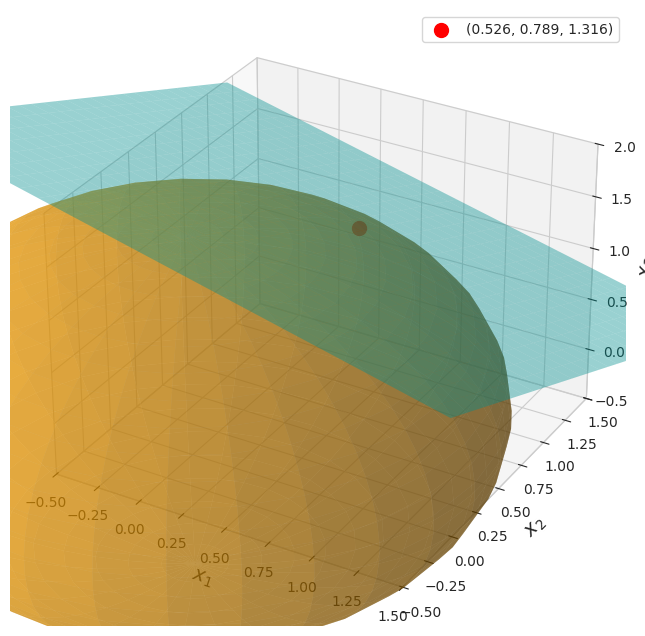

In [4]:
x_opt = np.array([10/19, 15/19, 25/19])
r_opt = np.linalg.norm(x_opt)

x = np.linspace(-1, 2, 30)
y = np.linspace(-1, 2, 30)
X, Y = np.meshgrid(x, y)
Z_plane = (10 - 2*X - 3*Y) / 5

phi = np.linspace(0, np.pi, 30)
theta = np.linspace(0, 2*np.pi, 30)
phi, theta = np.meshgrid(phi, theta)

r = r_opt
X_s = r*np.sin(phi)*np.cos(theta)
Y_s = r*np.sin(phi)*np.sin(theta)
Z_s = r*np.cos(phi)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(X, Y, Z_plane, alpha=0.4, color="cyan", rstride=1, cstride=1, linewidth=0)
ax.plot_surface(X_s, Y_s, Z_s, alpha=0.5, color="orange", rstride=1, cstride=1, linewidth=0)
ax.scatter(*x_opt, color="red", s=100, label=f'({x_opt[0]:.3f}, {x_opt[1]:.3f}, {x_opt[2]:.3f})')

ax.set_xlabel("$x_1$", fontsize=14)
ax.set_ylabel("$x_2$", fontsize=14)
ax.set_zlabel("$x_3$", fontsize=14)
ax.legend()
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.5, 1.5)
ax.set_zlim(-0.5, 2)

plt.show()

### SVM

#### Простой пример

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.datasets import make_classification

In [6]:
X, y = make_classification(
    n_samples=100,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    random_state=42
)

In [7]:
clf = svm.SVC(kernel='linear')
clf.fit(X, y)

SVC(kernel='linear')

In [8]:
print(clf.support_vectors_)

[[ 0.63356167 -1.17278867]
 [ 0.76916909 -1.0609667 ]
 [ 0.15559223  0.14096222]
 [-0.21198653 -0.20665158]
 [-0.85852241 -0.73473514]]


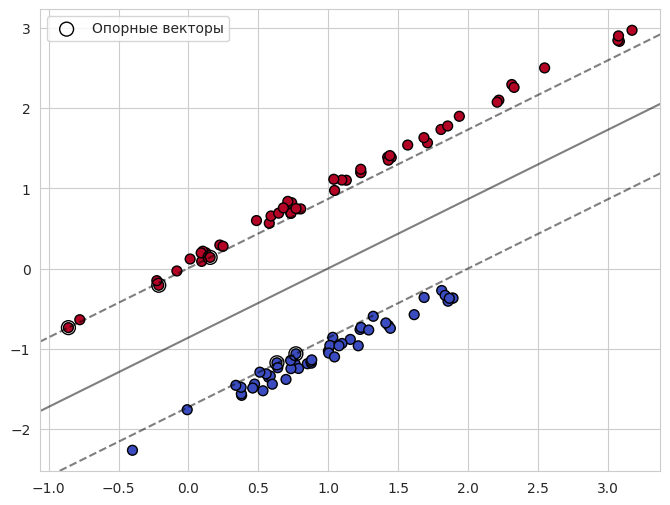

In [9]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, s=50, edgecolors="k")
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = clf.decision_function(xy).reshape(XX.shape)
ax.contour(XX, YY, Z, colors="k", levels=[-1, 0, 1], alpha=0.5,
           linestyles=["--", "-", "--"])
ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
           s=100, linewidth=1, facecolors="none", edgecolors="black", label="Опорные векторы")
plt.legend()
plt.show()

#### Kernel trick

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons

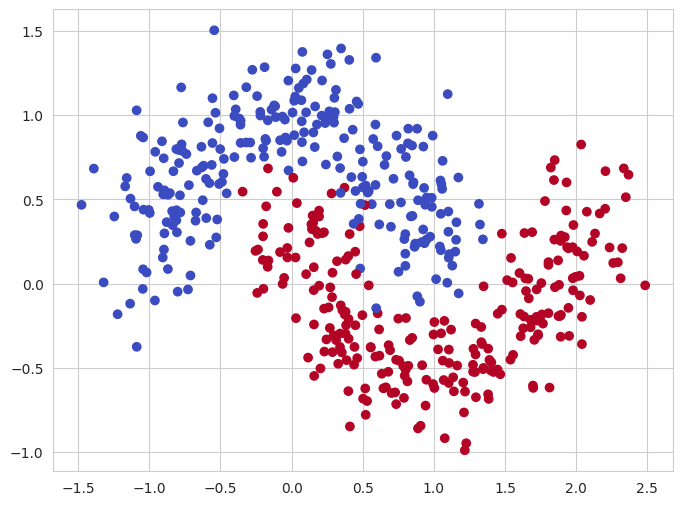

In [11]:
moons_points, moons_labels = make_moons(n_samples=500, noise=0.2, random_state=42)
plt.figure(figsize=(8, 6))
plt.scatter(moons_points[:, 0], moons_points[:, 1], c=moons_labels, cmap=plt.cm.coolwarm,)
plt.show()

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons, make_circles
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from mlxtend.plotting import plot_decision_regions

def train_model(model, X, y):
    model.fit(X, y)
    return model

def calculate_metrics(y_true, y_pred, average='weighted'):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average=average)
    recall = recall_score(y_true, y_pred, average=average)
    f1 = f1_score(y_true, y_pred, average=average)
    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

def plot_decision(X, y, models, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (model, title) in enumerate(zip(models, titles), 1):
        plt.subplot(1, len(models), i)
        plot_decision_regions(X=X, y=y, clf=model, legend=2)
        plt.title(title)
    plt.tight_layout()
    plt.show()

def logistic_regression_with_poly(X, y, degree=3, C=10, max_iter=500):
    lr_poly = make_pipeline(
        PolynomialFeatures(degree=degree),
        LogisticRegression(C=C, max_iter=max_iter, penalty='l2', random_state=42)
    )
    return train_model(lr_poly, X, y)

def run_experiment(X, y, models, model_names, metrics_average='weighted'):
    trained_models = [train_model(model, X, y) for model in models]

    # Decision regions
    plot_decision(X, y, trained_models, model_names)

    # Calculate metrics
    metrics = []
    for model in trained_models:
        y_pred = model.predict(X)
        metrics.append(calculate_metrics(y, y_pred, average=metrics_average))

    # Print metrics
    for name, metric in zip(model_names, metrics):
        print(f"{name} Metrics:")
        for key, value in metric.items():
            print(f"{key}: {value:.4f}")
        print("\n")

    return trained_models, metrics

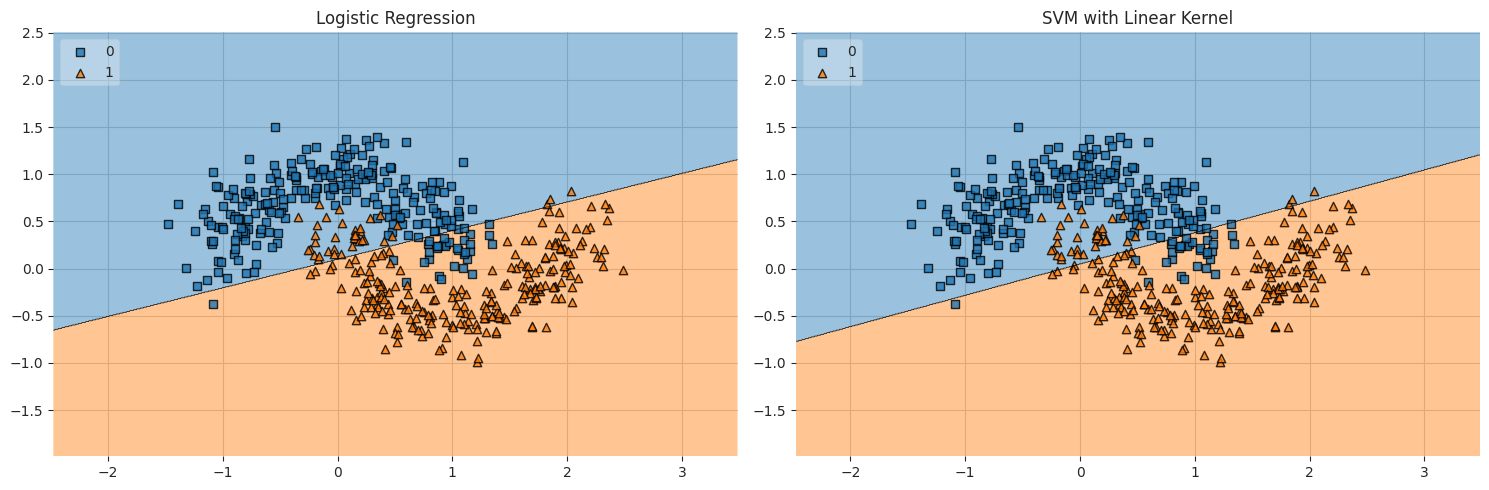

Logistic Regression Metrics:
Accuracy: 0.8560
Precision: 0.8560
Recall: 0.8560
F1-Score: 0.8560


SVM with Linear Kernel Metrics:
Accuracy: 0.8580
Precision: 0.8581
Recall: 0.8580
F1-Score: 0.8580




([LogisticRegression(C=1, max_iter=500, random_state=42),
  SVC(C=1, kernel='linear', random_state=42)],
 [{'Accuracy': 0.856,
   'Precision': 0.8560227854582693,
   'Recall': 0.856,
   'F1-Score': 0.8559976959631354},
  {'Accuracy': 0.858,
   'Precision': 0.8581432573029213,
   'Recall': 0.858,
   'F1-Score': 0.857985798579858}])

In [13]:
lr = LogisticRegression(C=1, max_iter=500, penalty='l2', random_state=42)
svm_linear = SVC(kernel="linear", C=1, random_state=42)
# knn, dt, rf, ...

models = [lr, svm_linear]
model_names = ["Logistic Regression", "SVM with Linear Kernel"]
run_experiment(moons_points, moons_labels, models, model_names)

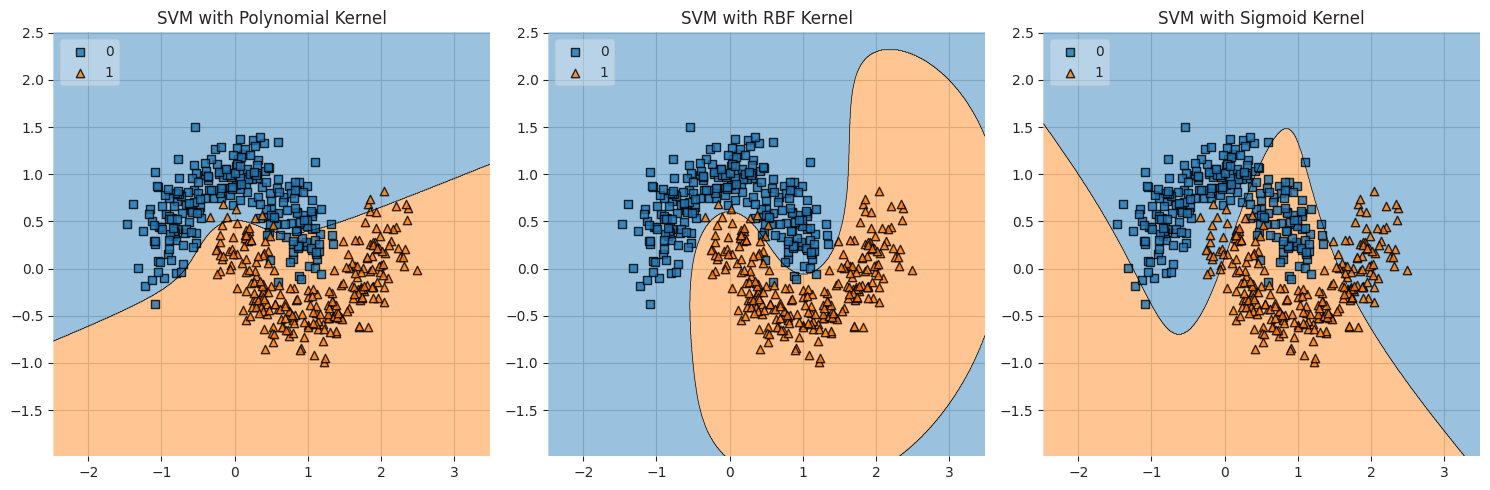

SVM with Polynomial Kernel Metrics:
Accuracy: 0.9060
Precision: 0.9101
Recall: 0.9060
F1-Score: 0.9058


SVM with RBF Kernel Metrics:
Accuracy: 0.9760
Precision: 0.9760
Recall: 0.9760
F1-Score: 0.9760


SVM with Sigmoid Kernel Metrics:
Accuracy: 0.6380
Precision: 0.6380
Recall: 0.6380
F1-Score: 0.6380




([SVC(C=1, kernel='poly', random_state=42),
  SVC(C=1, gamma=1, random_state=42),
  SVC(C=1, gamma=1, kernel='sigmoid', random_state=42)],
 [{'Accuracy': 0.906,
   'Precision': 0.9101010101010102,
   'Recall': 0.906,
   'F1-Score': 0.905764411027569},
  {'Accuracy': 0.976,
   'Precision': 0.9760304659498208,
   'Recall': 0.976,
   'F1-Score': 0.975999615993856},
  {'Accuracy': 0.638,
   'Precision': 0.6380198748619802,
   'Recall': 0.638,
   'F1-Score': 0.6379869675308311}])

In [14]:
svm_poly = SVC(kernel="poly", C=1, degree=3, random_state=42)
svm_rbf = SVC(kernel="rbf", C=1, gamma=1, random_state=42)
svm_sigmoid = SVC(kernel="sigmoid", C=1, gamma=1, random_state=42)

models = [svm_poly, svm_rbf, svm_sigmoid]
model_names = ["SVM with Polynomial Kernel", "SVM with RBF Kernel", "SVM with Sigmoid Kernel"]
run_experiment(moons_points, moons_labels, models, model_names)

In [15]:
lr_poly = make_pipeline(
    PolynomialFeatures(degree=3),
    LogisticRegression(C=10, max_iter=500, penalty='l2', random_state=42)
)

lr_poly.fit(moons_points, moons_labels)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=3)),
                ('logisticregression',
                 LogisticRegression(C=10, max_iter=500, random_state=42))])

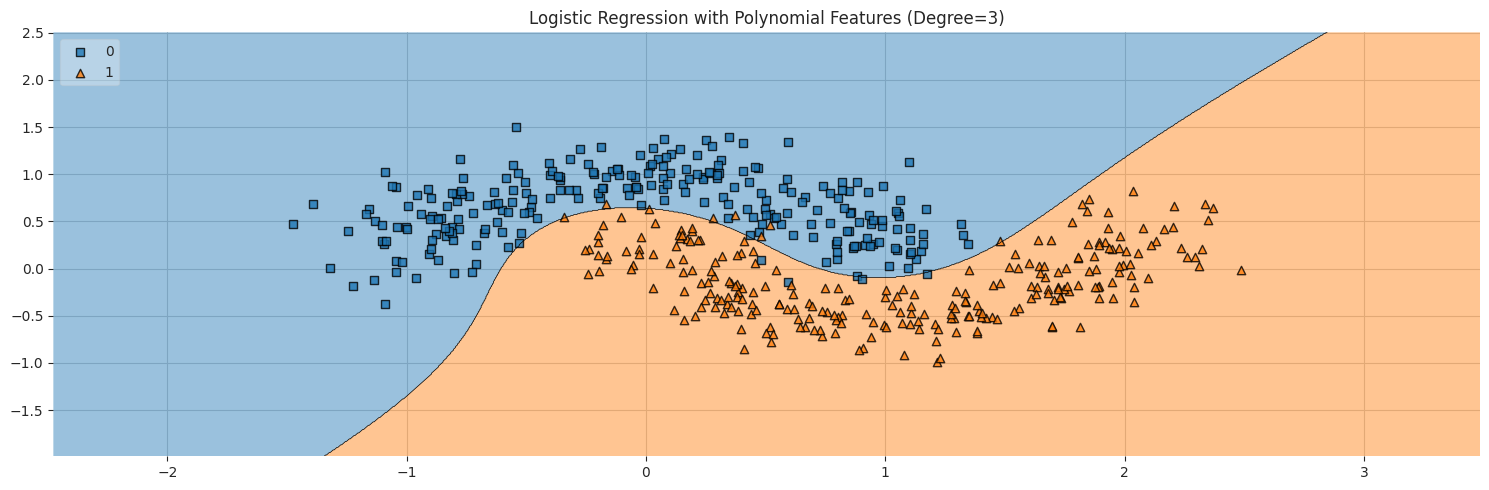

Logistic Regression with Polynomial Features (Degree=3) Metrics:
Accuracy: 0.9780
Precision: 0.9781
Recall: 0.9780
F1-Score: 0.9780




([Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=3)),
                  ('logisticregression',
                   LogisticRegression(C=10, max_iter=500, random_state=42))])],
 [{'Accuracy': 0.978,
   'Precision': 0.9780688419132355,
   'Recall': 0.978,
   'F1-Score': 0.9779992079714871}])

In [16]:
models = [lr_poly]
model_names = ["Logistic Regression with Polynomial Features (Degree=3)"]
run_experiment(moons_points, moons_labels, models, model_names)